# Project:- Student Success Predicitor  (Workflow)
* Load and Understand Data
* Preprocessing (Clean data)
* Features Scaling (if needed)
* Split the Data
* Train a Model
* Make Prediction
* Evaluate the Model
* Visualize results
* Improve/Experiment (Optional).....

In [4]:
import pandas as pd

df = pd.read_csv("student_dataset_10000_rows.csv")

print("sample Rows")
print(df.head())

print("DataSet Shape")
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')

print("dataset info")
print(df.info())

print("Summary Statistics")
print(df.describe(include='all'))

print("Missing Value")
print(df.isnull().sum())

sample Rows
   study_hours  attendance  sleep_hours  internet_usage  \
0            7          56            8               7   
1            4          69            5               3   
2           11          60            7               6   
3            8          99            9               8   
4            5          52            8               6   

   assignments_completed  previous_score  exam_score placement_status  
0                     10              62      100.00           Placed  
1                      8              56      100.00           Placed  
2                     10              45      100.00           Placed  
3                      4              55       90.17           Placed  
4                      8              40       78.82           Placed  
DataSet Shape
Rows: 10000, Columns: 8
dataset info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count 

In [5]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("student_dataset_10000_rows.csv")

print("Missing values in each column")
print(df.isnull().sum())

le = LabelEncoder()
df['placement_status'] = le.fit_transform(df["placement_status"])

print("After Encoding")
print(df.head())

print('Data-types after cleaning')
print(df.dtypes)

Missing values in each column
study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64
After Encoding
   study_hours  attendance  sleep_hours  internet_usage  \
0            7          56            8               7   
1            4          69            5               3   
2           11          60            7               6   
3            8          99            9               8   
4            5          52            8               6   

   assignments_completed  previous_score  exam_score  placement_status  
0                     10              62      100.00                 1  
1                      8              56      100.00                 1  
2                     10              45      100.00                 1  
3                      4              55       90.17                 1  
4     

Classification Report
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       345
           1       1.00      1.00      1.00      1655

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



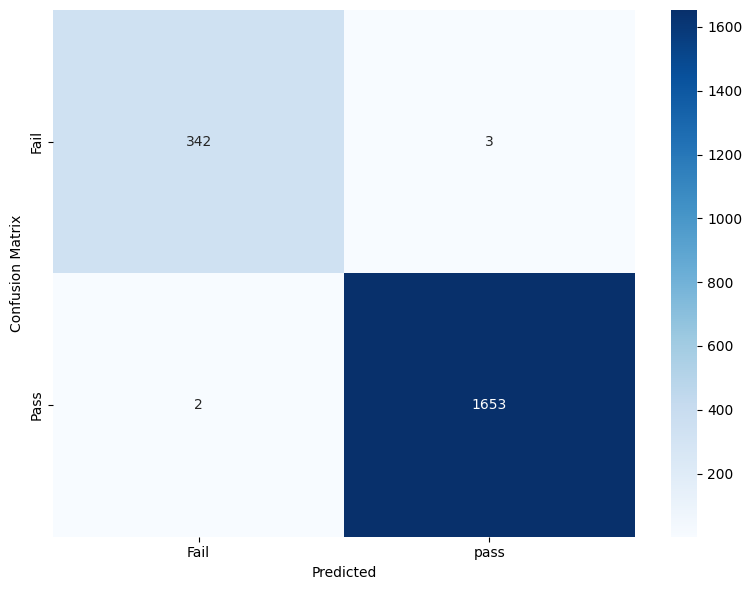

------Predict Your Result------
An error Occured


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder 
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

df = pd.read_csv("student_dataset_10000_rows.csv")

le = LabelEncoder()
df['placement_status'] = le.fit_transform(df["placement_status"])

features = ['study_hours', 'attendance','sleep_hours','internet_usage','assignments_completed','previous_score','exam_score']
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features] = scaler.fit_transform(df[features])

X = df_scaled[features]           # features
y = df_scaled['placement_status'] # target
X_train, X_test , y_train , y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Classification Report")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Fail", "pass"], yticklabels=["Fail", "Pass"])
plt.xlabel("Predicted")
plt.ylabel("Confusion Matrix")
plt.tight_layout()
plt.show()

print("------Predict Your Result------")
try:
    study_hours = float(input("Enter study hours: "))
    attendance = float(input("Enter study attendance: "))
    sleep_hours =float(input("Enter study sleep hours: "))
    internet_usage = float(input("Enter internet usage: "))
    assignments_completed = float(input("Enter study assignments completed: "))
    previous_score = float(input("Enter study previous score: "))
    exam_score = float(input("Enter study exam score: "))

    user_input_df = pd.DataFrame([{
        'StudyHours': study_hours,
        'Attendance': attendance,
        'sleepHour': sleep_hours,
        'Internet': internet_usage,
        'Assignments': assignments_completed,
        'ExamScore': exam_score
    }])

    user_input_scaled = scaler.transform(user_input_df)

    prediction = model.predict(user_input_df)

    result = "Pass" if prediction == 1 else "Fail"
    print("Prediction Based on Input: {result}")

except Exception as e:
    print("An error Occured")    